# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko,
                                                   add_model_name_to_df,
                                                       df_with_ground_truth_as_kind_of_model)

from halcyon.results.plot_from_df import plot_model_plots, plot_per_gene_mse_heatmap, rotate_x_tick_labels, wrap_titles

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

In [2]:
print(mlflow.get_tracking_uri())
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon comparing models and datasets")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

https://mlflow.cropresilience.org


In [14]:
# Later on add: e56b1774f68349209f3b7e672158fa01 for 100 genes
simulation_run_ids = ["d660c1d337c34d98a349605d9b4d5b47", '19ba6fc0e8094a66a68f2f67cdca2162']
run_df_list = []
for id in simulation_run_ids:
    parent_run_id_search_string = f"tags.mlflow.parentRunId= '{id}'" 
    run_df_list.append(mlflow.search_runs(filter_string=parent_run_id_search_string, output_format="pandas"))

metrics_df = pd.concat(run_df_list)
metrics_df.shape

(150, 39)

In [33]:
parent_run_params  = dict()
for parent_run_id in metrics_df['tags.mlflow.parentRunId'].unique():
    run = mlflow.get_run(parent_run_id)
    parent_run_params[parent_run_id] = run.data.params
params_df = pd.DataFrame.from_dict(parent_run_params, orient="index")
params_df.index.name = "tags.mlflow.parentRunId"
params_df.head()

,nr_genes,sparsity,num_modules,noise_level,seed
tags.mlflow.parentRunId,,,,,
d660c1d337c34d98a349605d9b4d5b47,20,0.1,2,MEDIUM,174
19ba6fc0e8094a66a68f2f67cdca2162,50,0.1,5,MEDIUM,174


In [34]:
metrics_df = metrics_df.merge(params_df, on="tags.mlflow.parentRunId", how="left")
metrics_df.head()

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.train_loss,metrics.train_single_ko_final_mse_loss,metrics.train_mse,metrics.train_single_ko_final_loss,...,tags.mlflow.parentRunId,tags.mlflow.user,tags.mlflow.source.name,tags.mlflow.runName,tags.mlflow.source.git.commit,nr_genes,sparsity,num_modules,noise_level,seed
0,329584d993a1447ca8daa7bfc1e84448,4,FINISHED,mlflow-artifacts:/4/329584d993a1447ca8daa7bfc1...,2026-03-25 08:06:11.810000+00:00,2026-03-25 09:36:12.144000+00:00,0.032359,0.025262,0.025266,0.032350,...,d660c1d337c34d98a349605d9b4d5b47,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20,0.1,2,MEDIUM,174
1,468bddfbe2924d8ca2cfccb18eb5205d,4,FINISHED,mlflow-artifacts:/4/468bddfbe2924d8ca2cfccb18e...,2026-03-25 08:04:24.235000+00:00,2026-03-25 08:45:11.870000+00:00,0.030599,0.024420,0.024433,0.030591,...,d660c1d337c34d98a349605d9b4d5b47,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20,0.1,2,MEDIUM,174
2,f2c8166e76ee453b97d74db78759ae4f,4,FINISHED,mlflow-artifacts:/4/f2c8166e76ee453b97d74db787...,2026-03-25 07:54:53.221000+00:00,2026-03-25 08:04:23.010000+00:00,0.053693,0.038566,0.038556,0.053572,...,d660c1d337c34d98a349605d9b4d5b47,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20,0.1,2,MEDIUM,174
3,09d8d032b66a42f2a463e875349c8780,4,FINISHED,mlflow-artifacts:/4/09d8d032b66a42f2a463e87534...,2026-03-25 07:54:51.926000+00:00,2026-03-25 08:35:28.900000+00:00,0.017532,0.017481,0.017532,0.017481,...,d660c1d337c34d98a349605d9b4d5b47,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20,0.1,2,MEDIUM,174
4,3b42473cb9a6474083c186af5c951943,4,FINISHED,mlflow-artifacts:/4/3b42473cb9a6474083c186af5c...,2026-03-25 07:54:51.301000+00:00,2026-03-25 08:24:39.869000+00:00,0.016479,0.016427,0.016479,0.016427,...,d660c1d337c34d98a349605d9b4d5b47,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20,0.1,2,MEDIUM,174


In [ ]:
params_that_should_be_float = ['params.lambda_l1', 'nr_genes']
for param_to_float in params_that_should_be_float:
    metrics_df[param_to_float] = metrics_df[param_to_float].astype('float')

In [68]:
metrics_df

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.train_loss,metrics.train_single_ko_final_mse_loss,metrics.train_mse,metrics.train_single_ko_final_loss,...,tags.mlflow.user,tags.mlflow.source.name,tags.mlflow.runName,tags.mlflow.source.git.commit,nr_genes,sparsity,num_modules,noise_level,seed,long_model_name
0,329584d993a1447ca8daa7bfc1e84448,4,FINISHED,mlflow-artifacts:/4/329584d993a1447ca8daa7bfc1...,2026-03-25 08:06:11.810000+00:00,2026-03-25 09:36:12.144000+00:00,0.032359,0.025262,0.025266,0.032350,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20.0,0.1,2,MEDIUM,174,PhoenixAddAndProdLayers_nr_layers_hidden_size1...
1,468bddfbe2924d8ca2cfccb18eb5205d,4,FINISHED,mlflow-artifacts:/4/468bddfbe2924d8ca2cfccb18e...,2026-03-25 08:04:24.235000+00:00,2026-03-25 08:45:11.870000+00:00,0.030599,0.024420,0.024433,0.030591,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20.0,0.1,2,MEDIUM,174,PhoenixAddAndProdLayers_nr_layers_hidden_size1...
2,f2c8166e76ee453b97d74db78759ae4f,4,FINISHED,mlflow-artifacts:/4/f2c8166e76ee453b97d74db787...,2026-03-25 07:54:53.221000+00:00,2026-03-25 08:04:23.010000+00:00,0.053693,0.038566,0.038556,0.053572,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20.0,0.1,2,MEDIUM,174,PhoenixAddAndProdLayers_nr_layers_hidden_size2...
3,09d8d032b66a42f2a463e875349c8780,4,FINISHED,mlflow-artifacts:/4/09d8d032b66a42f2a463e87534...,2026-03-25 07:54:51.926000+00:00,2026-03-25 08:35:28.900000+00:00,0.017532,0.017481,0.017532,0.017481,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20.0,0.1,2,MEDIUM,174,PhoenixAddAndProdLayers_nr_layers_hidden_size1...
4,3b42473cb9a6474083c186af5c951943,4,FINISHED,mlflow-artifacts:/4/3b42473cb9a6474083c186af5c...,2026-03-25 07:54:51.301000+00:00,2026-03-25 08:24:39.869000+00:00,0.016479,0.016427,0.016479,0.016427,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,8bb8450f082ff68a3a2104995d6e23c37a995730,20.0,0.1,2,MEDIUM,174,PhoenixAddAndProdLayers_nr_layers_hidden_size5...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,6b68d6743c6a41af95b60409144fbb85,4,FINISHED,mlflow-artifacts:/4/6b68d6743c6a41af95b6040914...,2026-03-25 10:08:32.817000+00:00,2026-03-25 13:15:00.387000+00:00,0.011576,0.009546,0.009555,0.011561,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,dba9432a31bacd74dbd6a300d44e57efb2176c68,50.0,0.1,5,MEDIUM,174,PhoenixAddAndProdLayers_nr_layers_hidden_size1...
146,678a48a3c71d460dab1c3212b0fc0bb7,4,FINISHED,mlflow-artifacts:/4/678a48a3c71d460dab1c3212b0...,2026-03-25 10:08:32.814000+00:00,2026-03-25 13:23:02.621000+00:00,0.014316,0.011632,0.011398,0.014547,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,dba9432a31bacd74dbd6a300d44e57efb2176c68,50.0,0.1,5,MEDIUM,174,PhoenixAddAndProdLayers_nr_layers_hidden_size2...
147,f5412e06be404028b81185738e315c68,4,FINISHED,mlflow-artifacts:/4/f5412e06be404028b81185738e...,2026-03-25 10:08:32.811000+00:00,2026-03-25 10:18:57.436000+00:00,0.071398,0.022762,0.022376,0.071439,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,CellBox,dba9432a31bacd74dbd6a300d44e57efb2176c68,50.0,0.1,5,MEDIUM,174,CellBox_nr_layers_hidden_size_synth_only_pos_l...
148,c2c9073af43f4f34a21e68f066e0772d,4,FINISHED,mlflow-artifacts:/4/c2c9073af43f4f34a21e68f066...,2026-03-25 10:08:32.810000+00:00,2026-03-25 15:03:11.491000+00:00,0.012318,0.009483,0.009532,0.012270,...,ben.noordijk@wur.nl,scripts/train_ml_models.py,PhoenixAddAndProdLayers,dba9432a31bacd74dbd6a300d44e57efb2176c68,50.0,0.1,5,MEDIUM,174,PhoenixAddAndProdLayers_nr_layers_hidden_size5...


In [16]:
test_mse_col_name = 'metrics.double_ko_final_mse_loss'

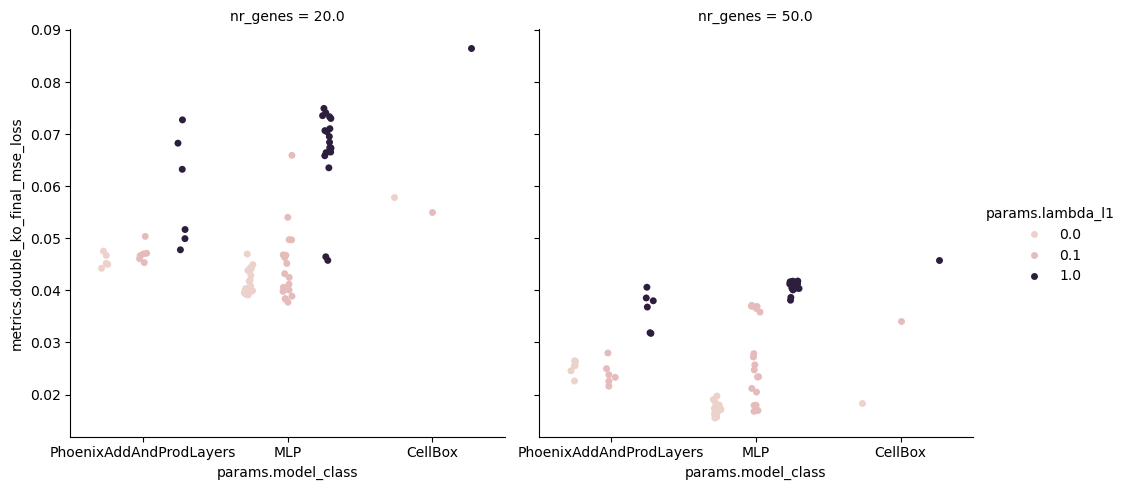

In [72]:
sns.catplot(data=metrics_df, y=test_mse_col_name, x='params.model_class', hue='params.lambda_l1', col='nr_genes', kind='strip', dodge=True)

In [67]:
metrics_df["long_model_name"] = metrics_df["params.model_class"] + '_nr_layers' + metrics_df["params.nr_layers"].fillna("") + "_hidden_size" + metrics_df["params.hidden_size"].fillna("") + "_synth_only_pos" +metrics_df["params.synthesis_only_positive"].fillna("").astype('str') + "_lambda" + metrics_df["params.lambda_l1"].astype('str')

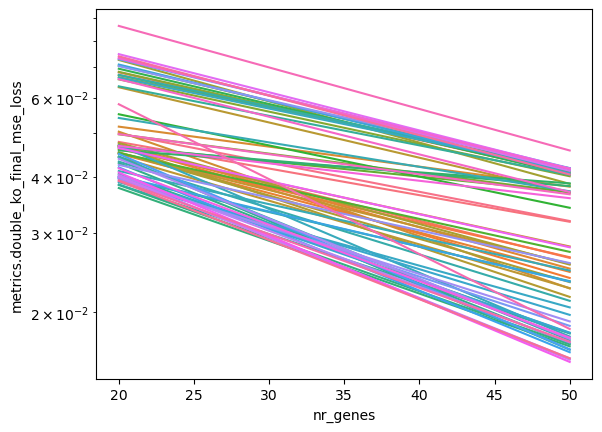

In [71]:
sns.lineplot(data=metrics_df, x='nr_genes', y=test_mse_col_name, hue='long_model_name', legend=False)
plt.yscale('log')

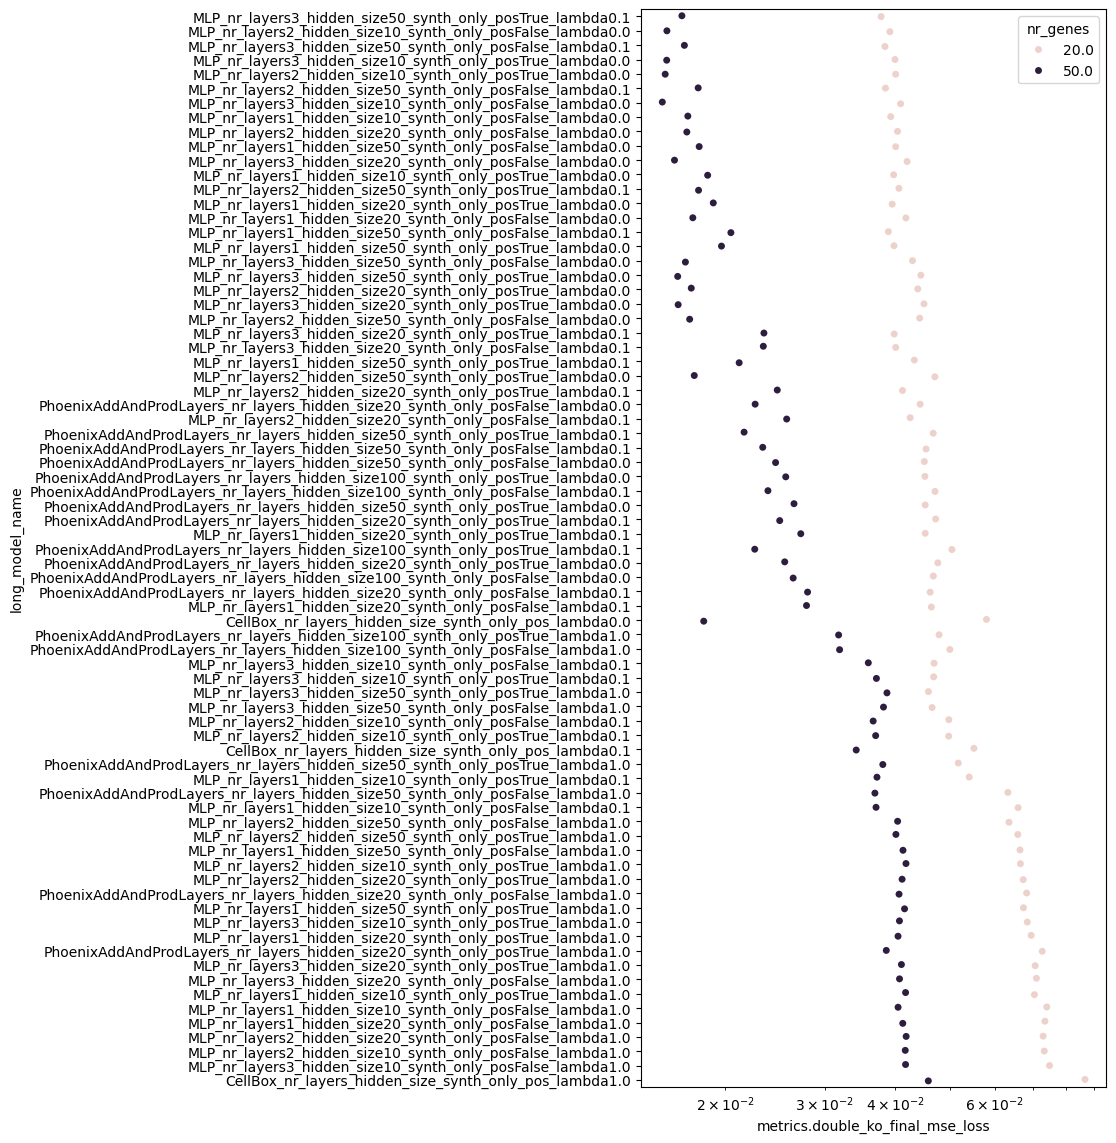

In [90]:
order = metrics_df.groupby("long_model_name")[test_mse_col_name].mean().sort_values().index

fig, ax = plt.subplots(figsize=(6, 14))
sns.stripplot(data=metrics_df, x=test_mse_col_name, y='long_model_name', hue='nr_genes', legend=True, ax=ax, order=order)
plt.xscale('log')